**Примеры из раздела 6.2**

Модель экспоненциального роста

In [1]:
import Pkg
Pkg.activate(; temp=true)  # временное пустое окружение
Pkg.add("DifferentialEquations")
using DifferentialEquations

  Activating new project at `/tmp/jl_NvPVZU`
   Resolving package versions...
    Updating `/tmp/jl_NvPVZU/Project.toml`
  [0c46a032] + DifferentialEquations v8.1.1
    Updating `/tmp/jl_NvPVZU/Manifest.toml`
  [47edcb42] + ADTypes v1.24.0
  [14f7f29c] + AMD v0.5.4
  [7d9f7c33] + Accessors v0.1.46
  [79e6a3ab] + Adapt v4.8.0
  [4fba245c] + ArrayInterface v7.30.2
  [b2a6c25c] + BinaryHeaps v1.1.0
  [70df07ce] + BracketingNonlinearSolve v1.12.8
  [38540f10] + CommonSolve v0.2.14
  [bbf7d656] + CommonSubexpressions v0.3.1
  [34da2185] + Compat v4.18.1
  [a33af91c] + CompositionsBase v0.1.2
  [2569d6c7] + ConcreteStructs v0.2.8
  [187b0558] + ConstructionBase v1.6.1
  [a8cc5b0e] + Crayons v4.2.0
  [9a962f9c] + DataAPI v1.16.0
  [e2d170a0] + DataValueInterfaces v1.0.0
  [8bb1440f] + DelimitedFiles v1.9.1
  [2b5f629d] + DiffEqBase v7.21.6
  [163ba53b] + DiffResults v1.1.0
  [b552c78f] + DiffRules v1.17.1
  [0c46a032] + DifferentialEquations v8.1.1
  [a0c0ee7d] + DifferentiationInterface v0.7

In [2]:
# задаём описание модели с начальными условиями:
a = 0.98
f(u,p,t) = a*u
u0 = 1.0
# задаём интервал времени:
tspan = (0.0,1.0)
# решение:
prob = ODEProblem(f,u0,tspan)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 5-element Vector{Float64}:
 0.0
 0.10042494449239292
 0.3521860297865888
 0.6934436122197829
 1.0
u: 5-element Vector{Float64}:
 1.0
 1.1034222047865465
 1.4121908713484919
 1.9730384457359198
 2.6644561424814266

   Resolving package versions...
   Installed ColorVectorSpace ─ v0.11.2
   Installed ColorTypes ─────── v0.12.5
   Installed StructUtils ────── v2.12.1
   Installed Parsers ────────── v3.0.6
   Installed JSON ───────────── v1.13.4
   Installed Colors ─────────── v0.13.4
   Installed ColorSchemes ───── v3.32.0
    Updating `/tmp/jl_NvPVZU/Project.toml`
  [91a5bcdd] + Plots v1.41.7
    Updating `/tmp/jl_NvPVZU/Manifest.toml`
  [66dad0bd] + AliasTables v1.1.3
  [35d6a980] + ColorSchemes v3.32.0
  [3da002f7] + ColorTypes v0.12.5
  [c3611d14] + ColorVectorSpace v0.11.2
  [5ae59095] + Colors v0.13.4
  [d38c429a] + Contour v0.6.3
  [864edb3b] + DataStructures v0.19.6
  [c87230d0] + FFMPEG v0.4.6
⌅ [53c48c17] + FixedPointNumbers v0.8.6
  [1fa38f19] + Format v1.3.7
  [28b8d3ca] + GR v0.73.27
  [1019f520] + JLFzf v0.1.11
  [682c06a0] + JSON v1.13.4
  [23fbe1c1] + Latexify v0.16.12
  [442fdcdd] + Measures v0.3.3
  [e1d29d7a] + Missings v1.2.1
  [69de0a69] + Parsers v3.0.6
  [ccf2f8ad] + PlotThem

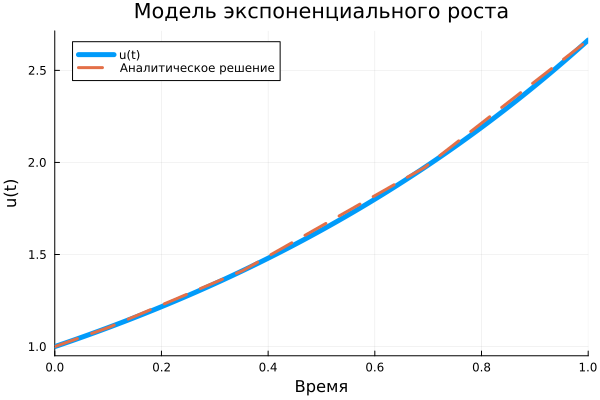

In [3]:
# подключаем необходимые пакеты:
Pkg.add("Plots")
using Plots
# строим графики:
plot(sol, linewidth=5,title="Модель экспоненциального роста", xaxis="Время",yaxis="u(t)",label="u(t)")
plot!(sol.t, t->1.0*exp(a*t),lw=3,ls=:dash,label="Аналитическое решение")

[1.0, 1.0412786454705882, 1.1547261208857074, 1.3239094565289573, 1.5363817850042807, 1.8214892991042442, 2.187139297776232, 2.6627632840763393, 2.6644562419335163]


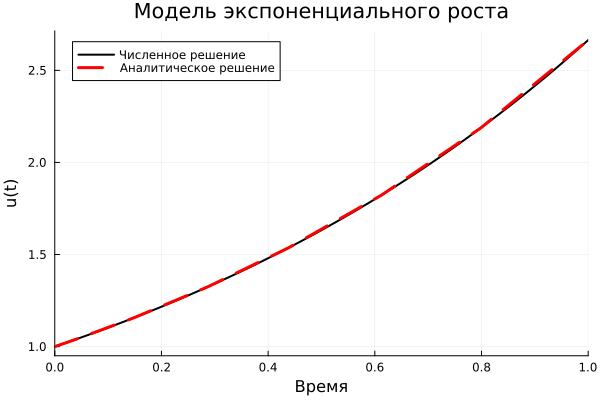

In [4]:
# задаём точность решения:
sol = solve(prob,abstol=1e-8,reltol=1e-8)
println(sol)
plot(sol, lw=2, color="black", title="Модель экспоненциального роста",
xaxis="Время",yaxis="u(t)",label="Численное решение")
plot!(sol.t, t->1.0*exp(a*t),lw=3,ls=:dash,color="red",label="Аналитическое решение")

Система Лоренца

In [5]:
# задаём описание модели:
function lorenz!(du,u,p,t)
    σ,ρ,β = p
    du[1] = σ*(u[2]-u[1])
    du[2] = u[1]*(ρ-u[3]) - u[2]
    du[3] = u[1]*u[2] - β*u[3]
end

lorenz! (generic function with 1 method)

In [6]:
# задаём начальное условие:
u0 = [1.0,0.0,0.0]
# задаём знанчения параметров:
p = (10,28,8/3)
# задаём интервал времени:
tspan = (0.0,100.0)
# решение:
prob = ODEProblem(lorenz!,u0,tspan,p)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 1309-element Vector{Float64}:
   0.0
   3.5678604836301404e-5
   0.001360418801727912
   0.0058427963210580585
   0.012740025740764261
   0.021714018522084766
   0.03403717376937933
   0.04999063087056864
   0.07064103756246295
   0.09680036031440067
   0.12950651684109013
   0.16617070570949674
   0.2063423305002916
   ⋮
  99.2489699836204
  99.31647232232814
  99.3848882345058
  99.44947702326306
  99.50896495769437
  99.56762259581639
  99.63129634444269
  99.70252522140233
  99.79452770979427
  99.88451636338145
  99.96663064589049
 100.0
u: 1309-element Vector{Vector{Float64}}:
 [1.0, 0.0, 0.0]
 [0.9996434557625105, 0.0009988049817849058, 1.781434788799189e-8]
 [0.9867445906548928, 0.03781126635142856, 2.552248396016225e-5]
 [0.9478380232292491, 0.15869450786525927, 0.0004491266858380763]
 [0.9012524885413848, 0.33528066879521534, 0.002001650346876804]
 [0.8622129040106976, 0.5523345224362657, 0.005421270536012252]
 [0.843213366

┌ Warning: To maintain consistency with solution indexing, keyword argument vars will be removed in a future version. Please use keyword argument idxs instead.
│   caller = ip:0x0
└ @ Core :-1


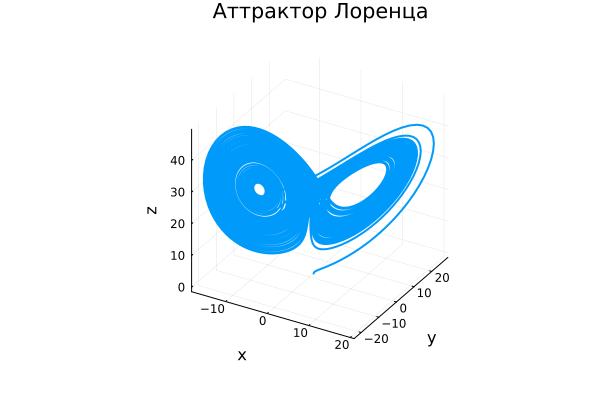

In [7]:
# строим график:
plot(sol, vars=(1,2,3), lw=2, title="Аттрактор Лоренца", xaxis="x",yaxis="y", zaxis="z",legend=false)

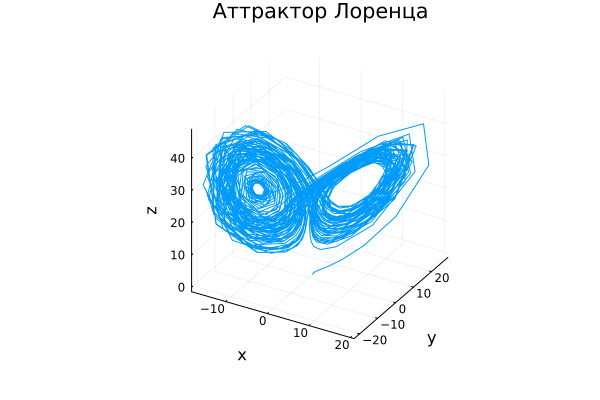

In [8]:
# отключаем интерполяцию:
plot(sol,vars=(1,2,3),denseplot=false, lw=1, title="Аттрактор Лоренца", xaxis="x",yaxis="y", zaxis="z",legend=false)

Модель Лотки–Вольтерры

In [9]:
# подключаем необходимые пакеты:
import Pkg
Pkg.add("ParameterizedFunctions")
using ParameterizedFunctions;

   Resolving package versions...
   Installed StarAlgebras ──────────── v0.3.1
   Installed Bijections ────────────── v0.2.2
   Installed StateSelection ────────── v1.11.1
   Installed MutableArithmetics ────── v1.9.4
   Installed DomainSets ────────────── v0.8.3
   Installed ModelingToolkitBase ───── v1.80.0
   Installed CompositeTypes ────────── v0.1.4
   Installed WeakCacheSets ─────────── v0.1.0
   Installed MultivariatePolynomials ─ v0.5.20
   Installed Symbolics ─────────────── v7.48.0
   Installed FunctionMaps ──────────── v0.1.2
   Installed ArrayLayouts ──────────── v1.16.1
   Installed JumpProcesses ─────────── v10.2.0
   Installed ModelingToolkit ───────── v11.46.1
   Installed ImplicitDiscreteSolve ─── v2.3.0
   Installed DynamicPolynomials ────── v0.6.8
   Installed ReadOnlyDicts ─────────── v1.0.1
   Installed ModelingToolkitTearing ── v1.20.9
   Installed DiffEqCallbacks ───────── v4.19.6
   Installed ParameterizedFunctions ── v5.27.2
   Installed ExproniconLite ────────

In [10]:
# задаём описание модели:
lv! = @ode_def LotkaVolterra begin
    dx = a*x - b*x*y
    dy = -c*y + d*x*y
end a b c d

LotkaVolterra{var"###ParameterizedDiffEqFunction#237", var"###ParameterizedTGradFunction#238", var"###ParameterizedJacobianFunction#239", Nothing, Nothing, System}(Main.var"##ParameterizedDiffEqFunction#237", LinearAlgebra.UniformScaling{Bool}(true), nothing, Main.var"##ParameterizedTGradFunction#238", Main.var"##ParameterizedJacobianFunction#239", nothing, nothing, nothing, nothing, nothing, nothing, nothing, [:x, :y], :t, nothing, Model ##Parameterized#236:
Equations (2):
  2 standard: see equations(##Parameterized#236)
Unknowns (2): see unknowns(##Parameterized#236)
  x(t)
  y(t)
Parameters (4): see parameters(##Parameterized#236)
  a
  b
  c
  d, nothing, nothing)

In [12]:
# задаём начальное условие:
u0 = [1.0,1.0]
# задаём знанчения параметров:
p = (1.5,1.0,3.0,1.0)
# задаём интервал времени:
tspan = (0.0,10.0)
# решение:
prob = ODEProblem(lv!,u0,tspan,p)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 34-element Vector{Float64}:
  0.0
  0.0776084743154256
  0.2326451370670694
  0.42911851563726466
  0.679082199936808
  0.9444046279774128
  1.2674601918628516
  1.6192914009389499
  1.986975548170207
  2.264090367998161
  2.512548683362107
  2.7468282919483245
  3.0380068768533777
  ⋮
  6.455761567904406
  6.780495212915041
  7.171039151123392
  7.584862444271911
  7.978067891667024
  8.483164641366129
  8.7192476918825
  8.949206449510495
  9.200184762926096
  9.438028551201107
  9.711807820573462
 10.0
u: 34-element Vector{Vector{Float64}}:
 [1.0, 1.0]
 [1.0454942346944578, 0.8576684823217128]
 [1.1758715885890039, 0.6394595702308832]
 [1.4196809580265157, 0.45699626144050676]
 [1.8767193976262218, 0.3247334288460736]
 [2.588250103514613, 0.2633625540395727]
 [3.8607090847970094, 0.27944581878759034]
 [5.750813064347343, 0.5220073551361049]
 [6.814978696356646, 1.9177834056716219]
 [4.392997771045282, 4.194671543390721]
 [2.100854

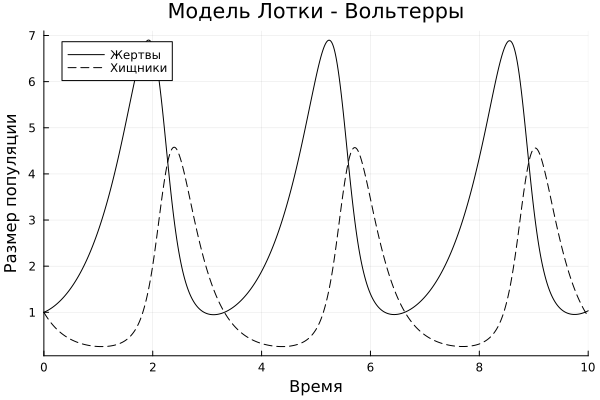

In [13]:
plot(sol, label = ["Жертвы" "Хищники"], color="black", ls=[:solid :dash], title="Модель Лотки - Вольтерры", xaxis="Время",yaxis="Размер популяции")

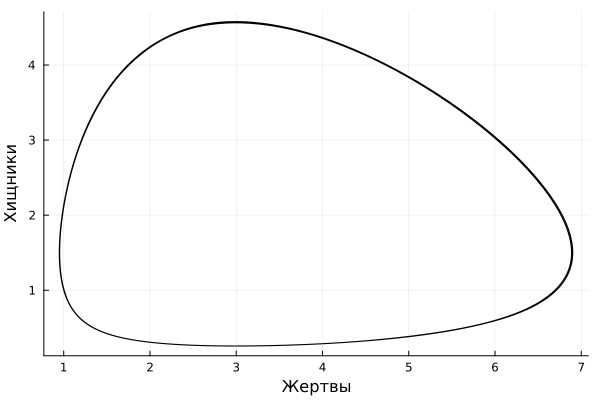

In [14]:
plot(sol,vars=(1,2), color="black", xaxis="Жертвы",yaxis="Хищники", legend=false)

**Задания для самостоятельного выполнения**

Задание №1

In [15]:
# задаём описание модели с начальными условиями:
f(u, p, t) = a*u
b = 0.05
c = 0.01
a = b - c
u0 = 1.0
# задаём интервал времени:
tspan = (0.0, 100.0)
# решение:
prob = ODEProblem(f, u0, tspan)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 11-element Vector{Float64}:
   0.0
   0.1904034517302618
   3.0036463921035685
   9.442205018928878
  17.92897958585829
  28.2569459395786
  40.554485797168866
  54.67191585411222
  70.53505239635247
  87.9904570647331
 100.0
u: 11-element Vector{Float64}:
  1.0
  1.007645214618887
  1.1276613154400372
  1.4589079824849056
  2.0486051601950175
  3.0965161729840567
  5.064111655793942
  8.907329823255296
 16.800300046331035
 33.771143324018794
 54.597493018754776

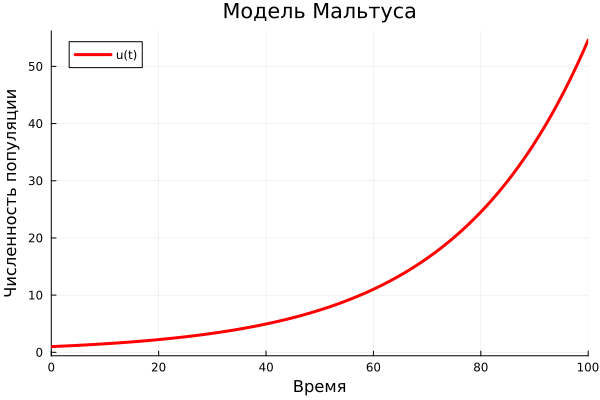

In [18]:
# графики
plot(sol, label="u(t)", xlabel="Время", ylabel="Численность популяции", title="Модель Мальтуса", c="red", linewidth=3)

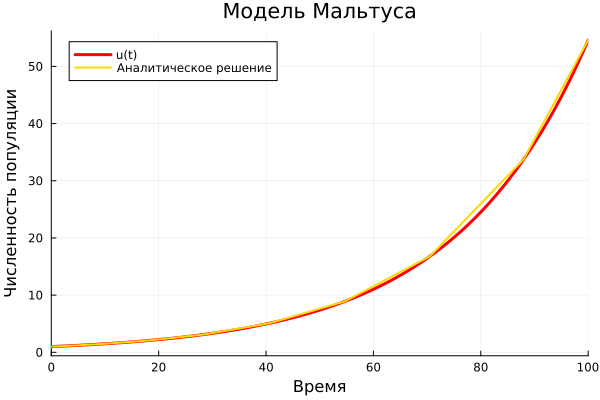

In [19]:
plot!(sol.t, t-> 1.0*exp(a*t), label="Аналитическое решение", xlabel="Время", ylabel="Численность популяции", 
    title="Модель Мальтуса", c="gold", linewidth=2)

[ Info: Saved animation to /home/eavernikovskaya/jupyter_project/lab06/maltus.gif


Plots.AnimatedGif("/home/eavernikovskaya/jupyter_project/lab06/maltus.gif")
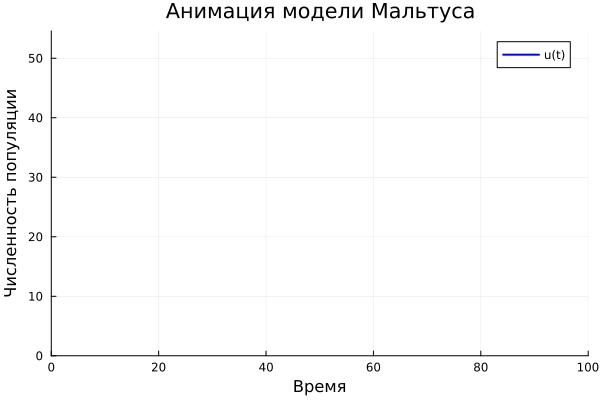

In [26]:
# анимация
anim = @animate for t in 0.0:0.5:100.0
    plot(sol.t[sol.t .<= t], sol.u[sol.t .<= t],
         label="u(t)", xlabel="Время", ylabel="Численность популяции",  title="Анимация модели Мальтуса", 
         xlim = (0, 100), ylim = (0, maximum(sol.u)), lw=2, linecolor=:blue)
end

# сохранение анимации
gif(anim, "/home/eavernikovskaya/jupyter_project/lab06/maltus.gif", fps=60)

Задание №2

In [27]:
# задаём описание модели с начальными условиями:
f(u, p, t) = r*u*(1 - u/k)
r = 0.55
k = 1000
u0 = 10
# задаём интервал времени:
tspan = (0.0, 50.0)
# решение:
prob = ODEProblem(f, u0, tspan)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 22-element Vector{Float64}:
  0.0
  0.1129299429223018
  0.5044961282126377
  1.0903125799504387
  1.7839293973166495
  2.643539021309861
  3.6397601946043756
  4.789434066161398
  6.092205872870974
  7.57634923088401
  9.364736511187038
 11.281451346133968
 13.467168491780495
 15.433790384213026
 17.72791217590949
 20.233430807718
 23.264000990554234
 26.87678496527625
 31.480131608178176
 37.42349243147255
 45.00355487386274
 50.0
u: 22-element Vector{Float64}:
  10.0
  10.633995132330723
  13.15583206272893
  18.066788337017112
  26.237986176013788
  41.44047735870745
  69.57397592659203
 123.36636021817363
 223.67047700917158
 394.5751871418989
 635.4132121211643
 833.3732659789179
 943.2892140733251
 980.0121776780079
 994.239139049787
 998.5307267707619
 999.7120841765968
 999.9541277654403
 999.9912346371632
 999.994323124556
 999.9826189743801
 999.9955435083631

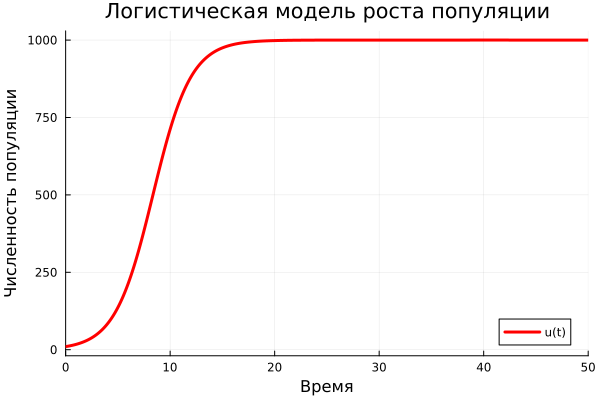

In [32]:
# графики
plot(sol, label="u(t)", xlabel="Время", ylabel="Численность популяции", title="Логистическая модель роста популяции", 
    c="red", linewidth=3)

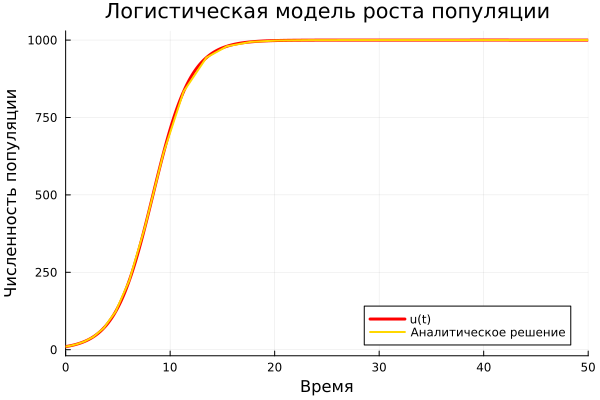

In [33]:
plot!(sol.t, t->k/(1 + ((k - 10.0)/10.0) * exp(-r*t)), label="Аналитическое решение", xlabel="Время", ylabel="Численность популяции", 
    title="Логистическая модель роста популяции", c="gold", linewidth=2)

[ Info: Saved animation to /home/eavernikovskaya/jupyter_project/lab06/logistic.gif


Plots.AnimatedGif("/home/eavernikovskaya/jupyter_project/lab06/logistic.gif")
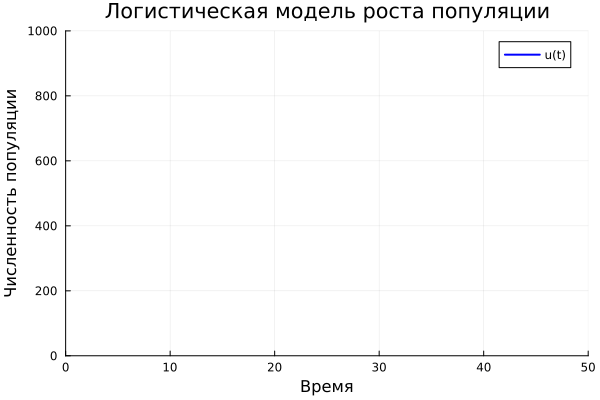

In [34]:
# анимация
anim = @animate for t in 0.0:0.5:100.0
    plot(sol.t[sol.t .<= t], sol.u[sol.t .<= t],
         label="u(t)", xlabel="Время", ylabel="Численность популяции",  title="Логистическая модель роста популяции", 
         xlim = (0, 50), ylim = (0, k), lw=2, linecolor=:blue)
end

# сохранение анимации
gif(anim, "/home/eavernikovskaya/jupyter_project/lab06/logistic.gif", fps=60)

Задание №3

In [35]:
function SIR(u, p, t)
    (S, I, R) = u
    (beta, v) = p
    N = S + I + R
    dS = -beta*I* S /N
    dI = beta*I*S / N - v*I
    dR = v*I
    return [dS, dI, dR]
end

SIR (generic function with 1 method)

In [65]:
# задаём описание модели с начальными условиями:
t = 0.1
tmax = 40.0
u0 = [990.0, 10.0, 0.0]
p = [0.3, 0.1]
# задаём интервал времени:
tspan = (0.0, tmax)
# решение:
prob = ODEProblem(SIR, u0, tspan, p)
sol = solve(prob, dt = t)

retcode: Success
Interpolation: 3rd order Hermite
t: 14-element Vector{Float64}:
  0.0
  0.1
  0.5824012849919981
  1.5797318705617496
  3.014676582968185
  4.848733720453
  7.161893101958043
  9.969614706472619
 13.362015902743405
 17.423961725880645
 22.291328096126623
 27.393697320043383
 33.280974810410484
 40.0
u: 14-element Vector{Vector{Float64}}:
 [990.0, 10.0, 0.0]
 [989.7001011274347, 10.198907523862736, 0.10099134870264877]
 [988.1689263140435, 11.213979704234312, 0.617093981722325]
 [984.5137609696064, 13.633883191370936, 1.8523558390227683]
 [977.8700049263745, 18.020594711983755, 4.109400361641935]
 [966.3134885735213, 25.614298790945156, 8.072212635533631]
 [945.0369179294822, 39.46943588722502, 15.493646183292885]
 [905.0372406890572, 65.05316697321658, 29.909592337726338]
 [828.2721932964511, 112.27355092172587, 59.45425578182312]
 [690.2022476515697, 189.55777159438605, 120.23998075404445]
 [489.18726842758963, 275.82838610151225, 234.98434547089846]
 [311.00527120979

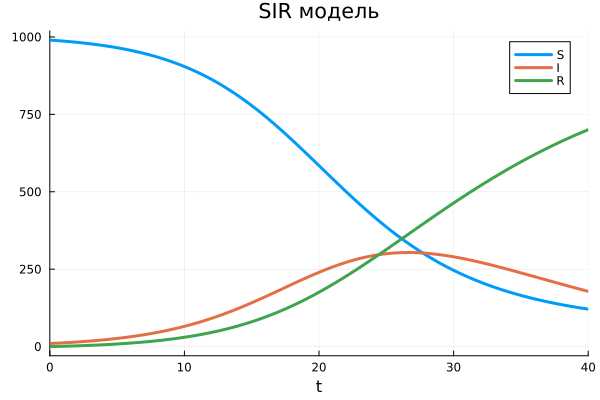

In [66]:
plot(sol, title="SIR модель", label = ["S" "I" "R"], lw=3)

Задание №4

In [67]:
function SEIR(u, p, t)
    (S, E, I, R) = u
    (beta, gamma, delta) = p
    N = S + E + I + R
    dS = -beta*I*S / N
    dE = beta*I*S / N - delta*E
    dI = delta*E - gamma*I
    dR = gamma*I
    return [dS, dE, dI, dR]
end

SEIR (generic function with 1 method)

In [68]:
# задаём описание модели с начальными условиями:
t = 0.1
tmax = 60.0
u0 = [980.0, 10.0, 10.0, 0.0]
p = [0.3, 0.1, 0.2]
# задаём интервал времени:
tspan = (0.0, tmax)
# решение:
prob = ODEProblem(SEIR, u0, tspan, p)
sol = solve(prob, dt = t)

retcode: Success
Interpolation: 3rd order Hermite
t: 16-element Vector{Float64}:
  0.0
  0.1
  1.0532780946453122
  3.1206591097165206
  5.968120156682696
  9.873311585334566
 13.996398817258425
 18.72932075283834
 23.726657019101328
 29.06221954952015
 34.62839373026964
 40.41301856290758
 46.24170097023329
 52.210353568125946
 58.53568738759886
 60.0
u: 16-element Vector{Vector{Float64}}:
 [980.0, 10.0, 10.0, 0.0]
 [979.7045702139083, 10.094486543548115, 10.100441771447743, 0.10050147109588672]
 [976.740515758888, 11.04481695112563, 11.104151364975685, 1.1105159250106849]
 [969.3091330196975, 13.431902799238046, 13.602634884644248, 3.6563292964202283]
 [956.4243344299115, 17.54501015222705, 17.91369136927418, 8.116964048587226]
 [932.4249877562238, 25.06079482085483, 25.926264276188828, 16.587953146732442]
 [896.7505902712829, 35.841573270976625, 37.81624317396281, 29.591593283777527]
 [839.0255526098445, 52.22145657832907, 56.98253597264323, 51.770454839183174]
 [755.3144439546102, 

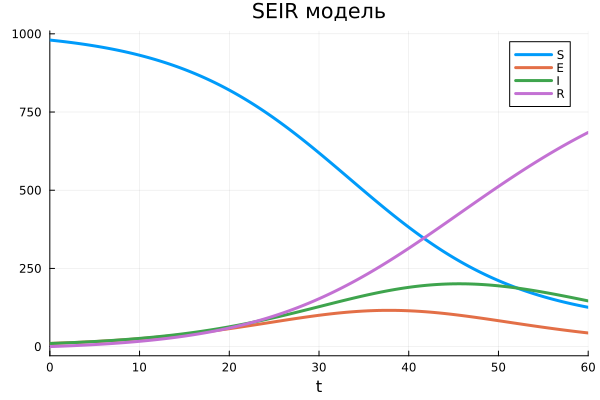

In [42]:
plot(sol, title="SEIR модель", label = ["S" "E" "I" "R"], lw=3)

Задание №5

In [43]:
# задаём описание модели с начальными условиями:
a, c, d = 2, 1, 5
t_max = 50

x1_0 = 0.5
x2_0 = 0.3

x1 = zeros(t_max)
x2 = zeros(t_max)

x1[1] = x1_0
x2[1] = x2_0

for t in 1:t_max-1
    x1[t+1] = a*x1[t] * (1 - x1[t]) - x1[t]*x2[t]
    x2[t+1] = -c*x2[t] + d*x1[t]*x2[t]
end

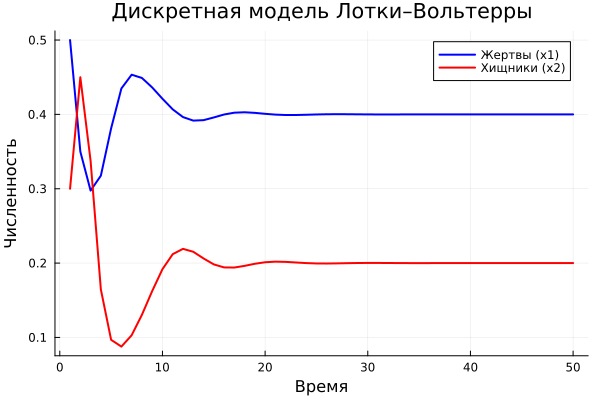

In [45]:
plot(1:t_max, x1, label="Жертвы (x1)", lw=2, color=:blue)
plot!(1:t_max, x2, label="Хищники (x2)", lw=2, color=:red,
    xlabel="Время", ylabel="Численность", title="Дискретная модель Лотки–Вольтерры")

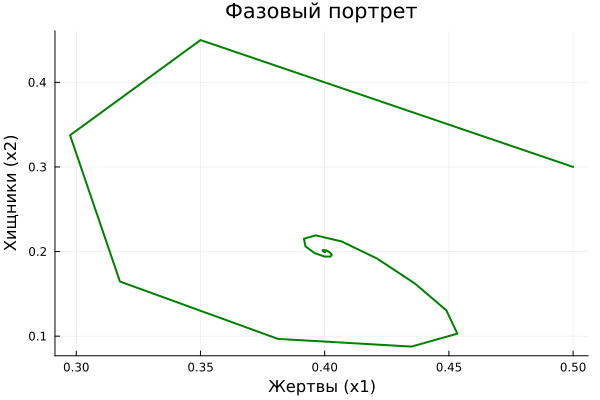

In [46]:
plot(x1, x2, xlabel="Жертвы (x1)", ylabel="Хищники (x2)", title="Фазовый портрет", legend=false, lw=2, color=:green)

Задание №6

In [47]:
function competition(u, p, t)
    (x, y) = u
    alpha, beta = p
    dx = alpha*x - beta*x*y
    dy = alpha*y - beta*x*y
    return [dx, dy]
end

competition (generic function with 1 method)

In [49]:
# задаём описание модели с начальными условиями:
u0 = [10.0, 5.0]
p = [1.0, 0.01]
# задаём интервал времени:
tspan = (0.0, 50.0)
# решение:
prob = ODEProblem(competition, u0, tspan, p)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 208-element Vector{Float64}:
  0.0
  0.10156702565895448
  0.3690043796479228
  0.7400119454078004
  1.1953815744365024
  1.7599692477963567
  2.412886445446606
  3.063506533141917
  3.6774889240081983
  4.28122310023126
  4.620222895222495
  4.853612056134569
  5.033649796600031
  ⋮
 47.26515298338002
 47.525906969663914
 47.78666095594781
 48.047414942231704
 48.3081689285156
 48.568922914799494
 48.82967690108339
 49.09043088736728
 49.35118487365118
 49.61193885993507
 49.87269284621897
 50.0
u: 208-element Vector{Vector{Float64}}:
 [10.0, 5.0]
 [11.010345520940295, 5.47582498640051]
 [14.150668599481978, 6.919198933147777]
 [19.898542260303216, 9.418740175158542]
 [29.80405411561744, 13.279967254661708]
 [47.882634089866585, 18.82139259174167]
 [79.84407888255649, 24.013672390832742]
 [130.54568427440677, 23.53433614563071]
 [213.251393705539, 15.518972173382133]
 [366.81885707427097, 5.179810499648214]
 [509.24939454152684, 1.6

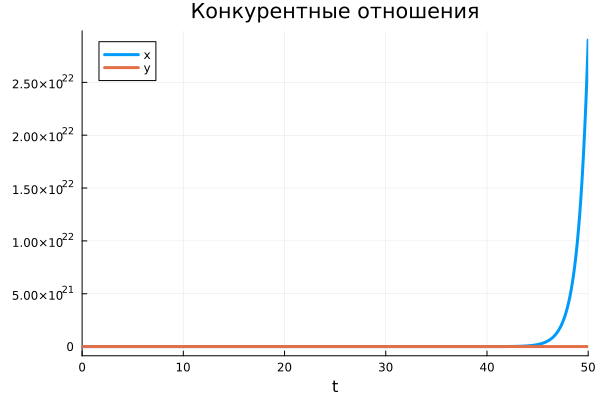

In [50]:
plot(sol, title="Конкурентные отношения", label = ["x" "y"], lw=3)

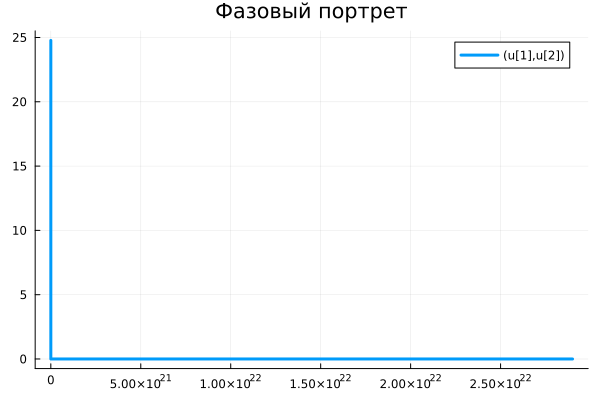

In [51]:
plot(sol, idxs=(1,2), title="Фазовый портрет", lw=3)

[ Info: Saved animation to /home/eavernikovskaya/jupyter_project/lab06/competition.gif


Plots.AnimatedGif("/home/eavernikovskaya/jupyter_project/lab06/competition.gif")
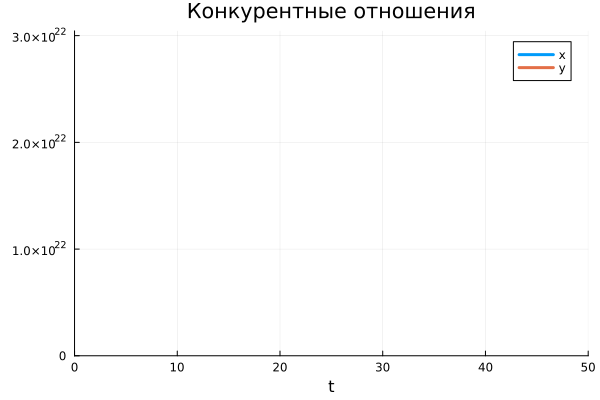

In [54]:
# анимация
sol = solve(prob, saveat = 0.5)
u_mat = hcat(sol.u...)'
anim = @animate for i in 1:length(sol.t)
    plot(sol.t[1:i], u_mat[1:i, :],
         xlims = (0, 50),
         ylims = (0, maximum(u_mat) * 1.05),
         xlabel = "t",
         title = "Конкурентные отношения",
         label = ["x" "y"],
         lw = 3)
end

# сохранение анимации
gif(anim, "/home/eavernikovskaya/jupyter_project/lab06/competition.gif", fps=60)

Задание №7

In [55]:
function harmonic(u, p, t)
    x, y = u
    gamma, omega = p
    dx = y
    dy = -2*gamma*y - omega^2*x
    return [dx, dy]
end

harmonic (generic function with 1 method)

In [56]:
# задаём описание модели с начальными условиями:
u0 = [-0.5, 0]
p = [0, 3.7]
# задаём интервал времени:
tspan = (0.0, 2*pi)
# решение:
prob = ODEProblem(harmonic, u0, tspan, p)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 37-element Vector{Float64}:
 0.0
 0.00014580043710971043
 0.006068371190769827
 0.03187680442793072
 0.08235320035571175
 0.15270221542111548
 0.24288200743938984
 0.35443387277479477
 0.48092359626033643
 0.6060765784046374
 0.764677297080636
 0.9324038526792283
 1.091664163000409
 ⋮
 3.871236920395963
 4.100343884882259
 4.331080242887555
 4.553702090566048
 4.7897037685158
 5.004138863516291
 5.244820278600507
 5.460538897077518
 5.70177162211643
 5.9210450448369585
 6.1612690117759215
 6.283185307179586
u: 37-element Vector{Vector{Float64}}:
 [-0.5, 0.0]
 [-0.49999992724529263, 0.0009980039436096415]
 [-0.4998739712910744, 0.04153451075509689]
 [-0.49652632241115713, 0.21769119519838295]
 [-0.4769674715241786, 0.5550250400081393]
 [-0.4222947726108616, 0.9905164645103046]
 [-0.311328130044275, 1.4476165471949356]
 [-0.12824568682615745, 1.7881108811251658]
 [0.1035563044160894, 1.8098864399246584]
 [0.31115472930979676, 1.4481266

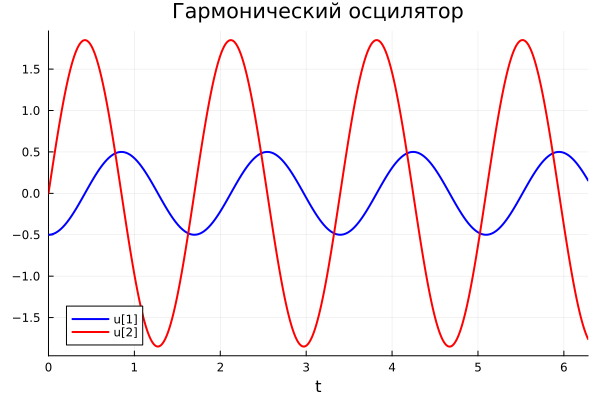

In [57]:
plot(sol, title="Гармонический осцилятор", c = ["blue" "red"], lw=2)

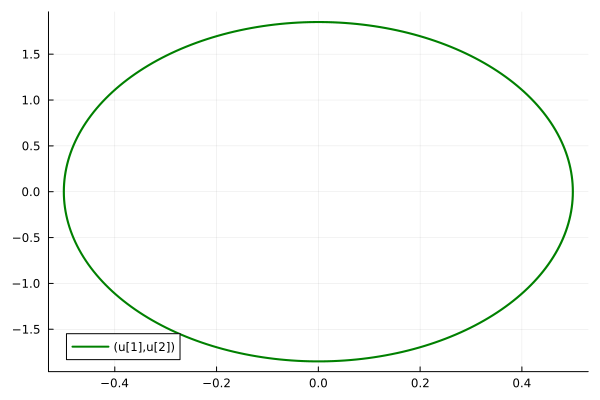

In [58]:
plot(sol, idxs=(1,2), color=:green, lw=2)

[ Info: Saved animation to /home/eavernikovskaya/jupyter_project/lab06/harmonic.gif


Plots.AnimatedGif("/home/eavernikovskaya/jupyter_project/lab06/harmonic.gif")
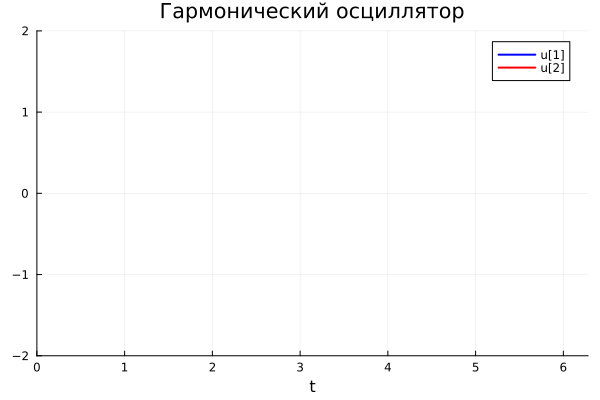

In [59]:
# анимация
sol_anim = solve(prob, saveat = 0.05)
u_mat = hcat(sol_anim.u...)'
anim = @animate for i in 1:length(sol_anim.t)
    plot(sol_anim.t[1:i], u_mat[1:i, :],
         xlims = (0, 2*pi),
         ylims = (-2.0, 2.0),
         xlabel = "t",
         title = "Гармонический осциллятор",
         label = ["u[1]" "u[2]"],
         c = ["blue" "red"],
         lw = 2)
end

# сохранение анимации
gif(anim, "/home/eavernikovskaya/jupyter_project/lab06/harmonic.gif", fps=60)

Задание №8

In [60]:
# задаём описание модели с начальными условиями:
u0 = [-0.5, 1]
p = [0.2, 3.7]
# задаём интервал времени:
tspan = (0.0, 5*pi)
# решение:
prob = ODEProblem(harmonic, u0, tspan, p)
sol = solve(prob)

retcode: Success
Interpolation: 3rd order Hermite
t: 76-element Vector{Float64}:
  0.0
  0.05845150294965944
  0.14182777017658438
  0.24111928090860568
  0.3554444520798903
  0.46982746944261355
  0.6191397099901007
  0.7764089673710999
  0.9300985494253451
  1.1143437148955984
  1.300520631138441
  1.4850037743426237
  1.6923292870732898
  ⋮
 13.254291855687846
 13.471917842161632
 13.705025134863671
 13.928252258663981
 14.159485768753346
 14.38649459905694
 14.60847978646456
 14.84179146025617
 15.060377725128145
 15.296179334658003
 15.505692530123312
 15.707963267948966
u: 76-element Vector{Vector{Float64}}:
 [-0.5, 1.0]
 [-0.4311182769867439, 1.3463391350841247]
 [-0.30233145901343217, 1.7163503011377184]
 [-0.11907509095434965, 1.9318845421968738]
 [0.10077113845071295, 1.8571478440225864]
 [0.2935109890585209, 1.4654803792125108]
 [0.45246775801063693, 0.6177923717294804]
 [0.468471213507099, -0.4091578435524641]
 [0.33846958467877863, -1.2282521945825335]
 [0.0629704797859261

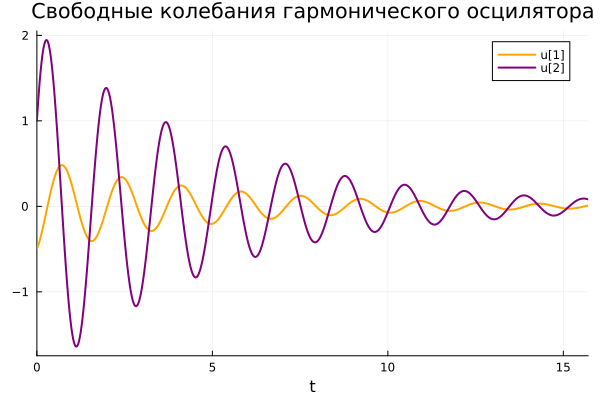

In [62]:
plot(sol, title="Свободные колебания гармонического осцилятора", c = ["orange" "purple"], lw=2)

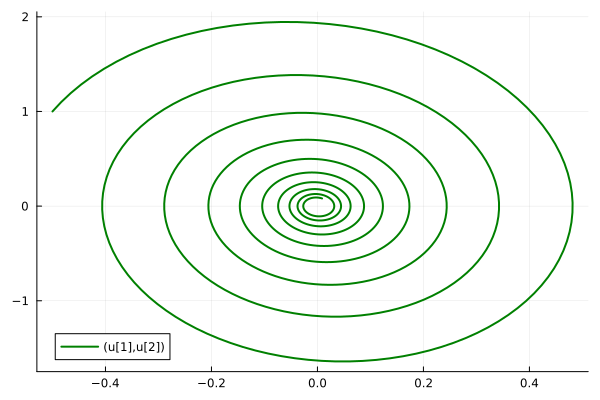

In [63]:
plot(sol, idxs=(1,2), color=:green, lw=2)

[ Info: Saved animation to /home/eavernikovskaya/jupyter_project/lab06/damped_harmonic.gif


Plots.AnimatedGif("/home/eavernikovskaya/jupyter_project/lab06/damped_harmonic.gif")
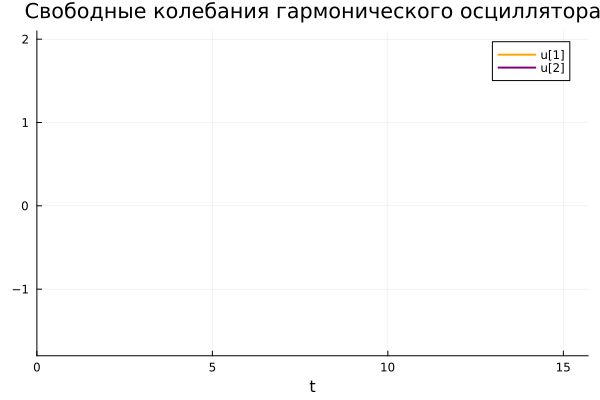

In [64]:
# анимация
sol_anim = solve(prob, saveat = 0.08)
u_mat = hcat(sol_anim.u...)'
anim = @animate for i in 1:length(sol_anim.t)
    plot(sol_anim.t[1:i], u_mat[1:i, :],
         xlims = (0, 5*pi),
         ylims = (-1.8, 2.1),
         xlabel = "t",
         title = "Свободные колебания гармонического осциллятора",
         label = ["u[1]" "u[2]"],
         c = ["orange" "purple"],
         lw = 2)
end

# сохранение анимации
gif(anim, "/home/eavernikovskaya/jupyter_project/lab06/damped_harmonic.gif", fps=60)